In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
sns.set(style='darkgrid')
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure
from scipy import stats
from sklearn.linear_model import LogisticRegression


Basic Exploration

In [2]:
india_flood=pd.read_csv('flood_risk_dataset_india.csv')
india_flood

,Latitude,Longitude,Rainfall (mm),Temperature (°C),Humidity (%),River Discharge (m³/s),Water Level (m),Elevation (m),Land Cover,Soil Type,Population Density,Infrastructure,Historical Floods,Flood Occurred
0,18.861663,78.835584,218.999493,34.144337,43.912963,4236.182888,7.415552,377.465434,Water Body,Clay,7276.742184,1,0,1
1,35.570715,77.654451,55.353599,28.778774,27.585422,2472.585219,8.811019,7330.608875,Forest,Peat,6897.736956,0,1,0
2,29.227824,73.108463,103.991908,43.934956,30.108738,977.328053,4.631799,2205.873488,Agricultural,Loam,4361.518494,1,1,1
3,25.361096,85.610733,198.984191,21.569354,34.453690,3683.208933,2.891787,2512.277800,Desert,Sandy,6163.069701,1,1,0
4,12.524541,81.822101,144.626803,32.635692,36.292267,2093.390678,3.188466,2001.818223,Agricultural,Loam,6167.964591,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,32.872024,93.434120,285.682635,37.621017,69.795616,4830.703665,5.943965,2850.197900,Agricultural,Clay,6943.559433,0,0,0
9996,34.027756,69.357605,224.347263,37.935808,38.095486,1866.199787,9.466158,3314.692947,Forest,Clay,3011.997459,1,0,0
9997,35.454530,76.807256,5.836759,23.087083,79.919607,1523.374305,9.209185,3377.296962,Desert,Clay,7149.938303,1,0,1
9998,19.527152,80.856280,120.301453,28.029593,61.680873,2036.812638,2.004644,1146.986151,Water Body,Sandy,906.031452,1,0,1


In [3]:
india_flood.head(5)

,Latitude,Longitude,Rainfall (mm),Temperature (°C),Humidity (%),River Discharge (m³/s),Water Level (m),Elevation (m),Land Cover,Soil Type,Population Density,Infrastructure,Historical Floods,Flood Occurred
0,18.861663,78.835584,218.999493,34.144337,43.912963,4236.182888,7.415552,377.465434,Water Body,Clay,7276.742184,1,0,1
1,35.570715,77.654451,55.353599,28.778774,27.585422,2472.585219,8.811019,7330.608875,Forest,Peat,6897.736956,0,1,0
2,29.227824,73.108463,103.991908,43.934956,30.108738,977.328053,4.631799,2205.873488,Agricultural,Loam,4361.518494,1,1,1
3,25.361096,85.610733,198.984191,21.569354,34.453690,3683.208933,2.891787,2512.277800,Desert,Sandy,6163.069701,1,1,0
4,12.524541,81.822101,144.626803,32.635692,36.292267,2093.390678,3.188466,2001.818223,Agricultural,Loam,6167.964591,1,0,0


In [4]:
india_flood.tail(5)

,Latitude,Longitude,Rainfall (mm),Temperature (°C),Humidity (%),River Discharge (m³/s),Water Level (m),Elevation (m),Land Cover,Soil Type,Population Density,Infrastructure,Historical Floods,Flood Occurred
9995,32.872024,93.434120,285.682635,37.621017,69.795616,4830.703665,5.943965,2850.197900,Agricultural,Clay,6943.559433,0,0,0
9996,34.027756,69.357605,224.347263,37.935808,38.095486,1866.199787,9.466158,3314.692947,Forest,Clay,3011.997459,1,0,0
9997,35.454530,76.807256,5.836759,23.087083,79.919607,1523.374305,9.209185,3377.296962,Desert,Clay,7149.938303,1,0,1
9998,19.527152,80.856280,120.301453,28.029593,61.680873,2036.812638,2.004644,1146.986151,Water Body,Sandy,906.031452,1,0,1
9999,14.297072,72.995680,77.219394,29.622711,88.936537,2614.166967,0.991856,8381.595028,Desert,Clay,4530.770301,1,1,1


In [5]:
india_flood.describe()


,Latitude,Longitude,Rainfall (mm),Temperature (°C),Humidity (%),River Discharge (m³/s),Water Level (m),Elevation (m),Population Density,Infrastructure,Historical Floods,Flood Occurred
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,22.330627,82.631366,150.015118,29.961401,59.749104,2515.722946,5.017881,4417.138177,5021.468442,0.502000,0.498700,0.505700
std,8.341274,8.389542,86.032127,8.669838,23.142734,1441.706442,2.876579,2530.245421,2882.591520,0.500021,0.500023,0.499993
min,8.000337,68.004575,0.014437,15.000166,20.001339,0.042161,0.002701,1.150340,2.289000,0.000000,0.000000,0.000000
25%,15.143537,75.364428,76.124373,22.405717,39.541778,1284.782376,2.538847,2229.681903,2491.766601,0.000000,0.000000,0.000000
50%,22.283330,82.671007,150.620428,30.000907,59.497375,2530.451944,5.042094,4417.199760,5074.392880,1.000000,0.000000,1.000000
75%,29.460184,89.937897,223.402156,37.413488,80.038163,3767.229861,7.524692,6616.729065,7474.228752,1.000000,1.000000,1.000000
max,36.991813,96.997820,299.970293,44.993681,99.997772,4999.698480,9.996899,8846.894877,9999.169530,1.000000,1.000000,1.000000


In [6]:
india_flood.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Latitude                10000 non-null  float64
 1   Longitude               10000 non-null  float64
 2   Rainfall (mm)           10000 non-null  float64
 3   Temperature (°C)        10000 non-null  float64
 4   Humidity (%)            10000 non-null  float64
 5   River Discharge (m³/s)  10000 non-null  float64
 6   Water Level (m)         10000 non-null  float64
 7   Elevation (m)           10000 non-null  float64
 8   Land Cover              10000 non-null  str    
 9   Soil Type               10000 non-null  str    
 10  Population Density      10000 non-null  float64
 11  Infrastructure          10000 non-null  int64  
 12  Historical Floods       10000 non-null  int64  
 13  Flood Occurred          10000 non-null  int64  
dtypes: float64(9), int64(3), str(2)
memory usage: 1.1 

Data Cleaning

In [7]:
india_flood.isnull().sum()

Latitude                  0
Longitude                 0
Rainfall (mm)             0
Temperature (°C)          0
Humidity (%)              0
River Discharge (m³/s)    0
Water Level (m)           0
Elevation (m)             0
Land Cover                0
Soil Type                 0
Population Density        0
Infrastructure            0
Historical Floods         0
Flood Occurred            0
dtype: int64

In [12]:
india_flood[india_flood.duplicated()]

,Latitude,Longitude,Rainfall (mm),Temperature (°C),Humidity (%),River Discharge (m³/s),Water Level (m),Elevation (m),Land Cover,Soil Type,Population Density,Infrastructure,Historical Floods,Flood Occurred


In [14]:
india_flood["Land Cover"] = india_flood["Land Cover"].astype("category").cat.codes
india_flood["Soil Type"] = india_flood["Soil Type"].astype("category").cat.codes

india_flood.head(15)

,Latitude,Longitude,Rainfall (mm),Temperature (°C),Humidity (%),River Discharge (m³/s),Water Level (m),Elevation (m),Land Cover,Soil Type,Population Density,Infrastructure,Historical Floods,Flood Occurred
0,18.861663,78.835584,218.999493,34.144337,43.912963,4236.182888,7.415552,377.465434,4,0,7276.742184,1,0,1
1,35.570715,77.654451,55.353599,28.778774,27.585422,2472.585219,8.811019,7330.608875,2,2,6897.736956,0,1,0
2,29.227824,73.108463,103.991908,43.934956,30.108738,977.328053,4.631799,2205.873488,0,1,4361.518494,1,1,1
3,25.361096,85.610733,198.984191,21.569354,34.453690,3683.208933,2.891787,2512.277800,1,3,6163.069701,1,1,0
4,12.524541,81.822101,144.626803,32.635692,36.292267,2093.390678,3.188466,2001.818223,0,1,6167.964591,1,0,0
5,12.523841,93.105329,221.571312,36.006300,39.380945,2973.137417,6.969483,7433.062836,0,1,5377.538809,0,0,1
6,9.684425,68.931178,288.362370,39.766935,40.436802,536.326451,5.675580,8661.324855,4,4,6039.090369,0,0,1
7,33.119108,86.672170,34.964006,27.209131,56.457308,3157.919948,4.864941,6681.891487,0,0,3994.453680,0,1,1
8,25.432335,90.125517,212.870315,35.607657,60.765855,1867.752445,2.027741,7287.016909,2,4,6782.941225,0,0,0
9,28.534105,90.025111,69.103247,24.096044,44.710337,1670.948749,8.754557,5490.188075,3,4,2270.032224,0,1,0


Data Visulization

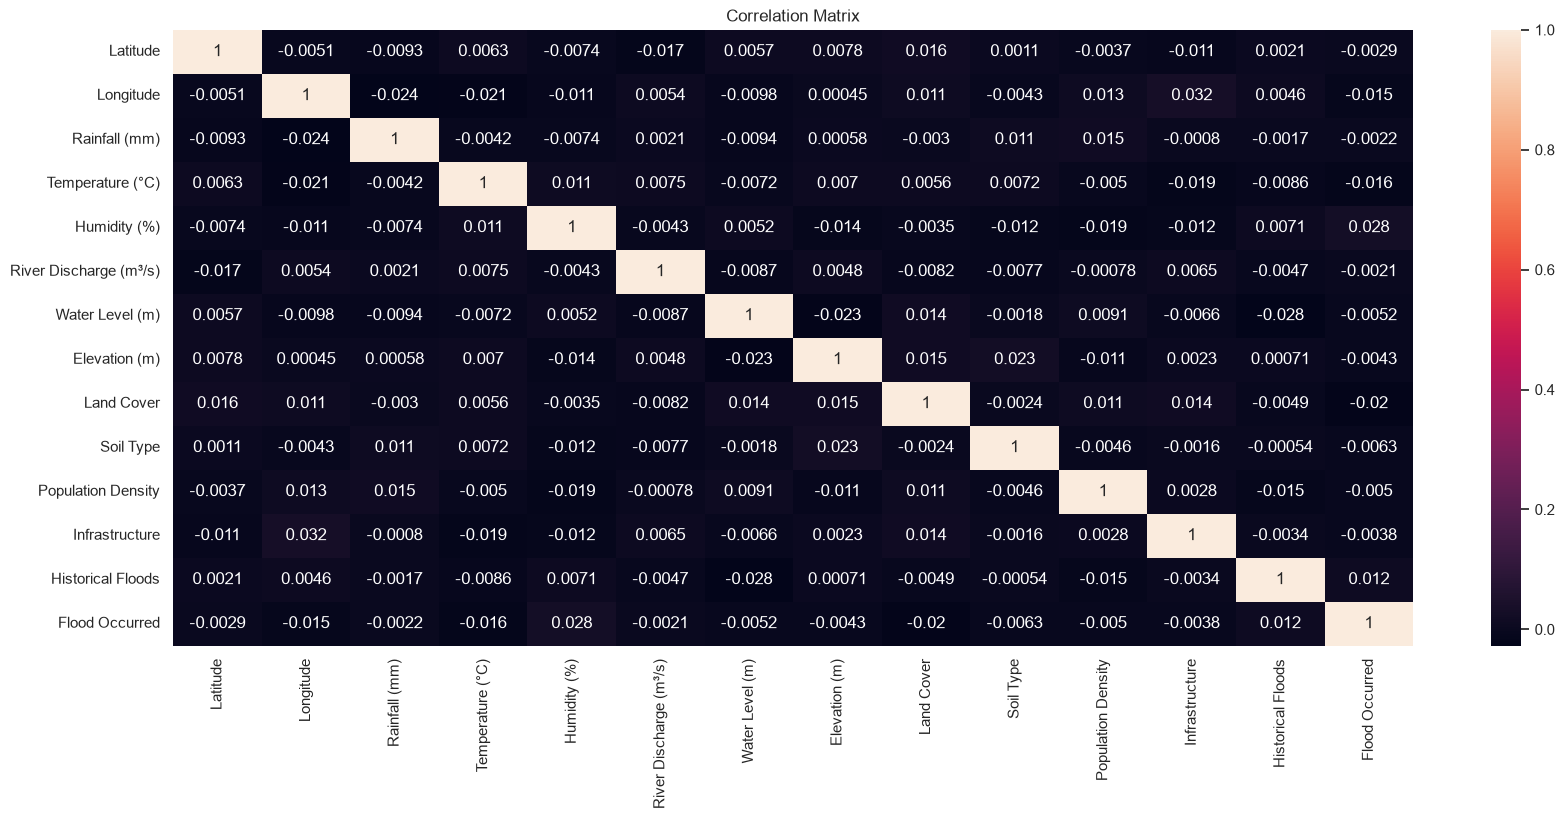

In [15]:
#Correlation matrix (heatmap)

plt.figure(figsize=(20,8))
sns.heatmap(india_flood.corr(),annot=True)
plt.title("Correlation Matrix")
plt.show()

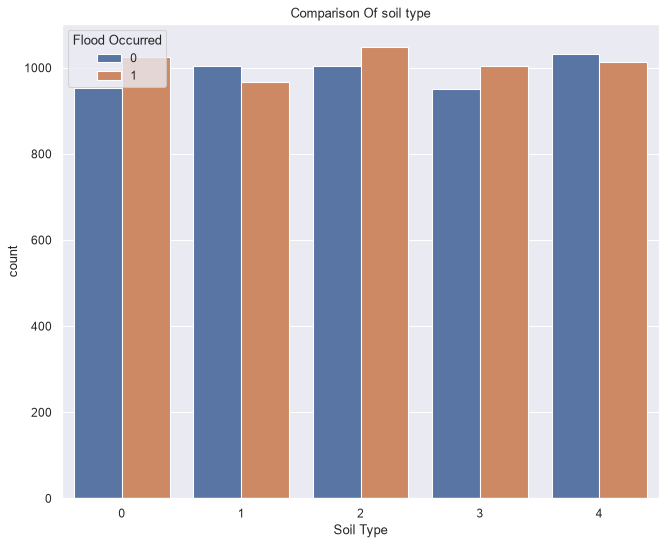

In [19]:
#Count Plot

plt.figure(figsize=(10,8), dpi=77)
sns.countplot(x=india_flood['Soil Type'],hue=india_flood['Flood Occurred'])
plt.title("Comparison Of soil type")
plt.show()

This graph shows that soil type has virtually no impact on whether a flood occurs or not in this dataset.The x-axis represents five different soil types (0 to 4). For every single soil type, the blue bar (no flood) and the orange bar (flood occurred) are almost identical in height, each counting around 1,000 instances.

This means that regardless of the soil type, the chance of a flood occurring remains roughly 50/50. Consequently, soil type alone cannot predict flooding; you will need to rely on other variables like rainfall, water levels, or elevation to determine flood risk.

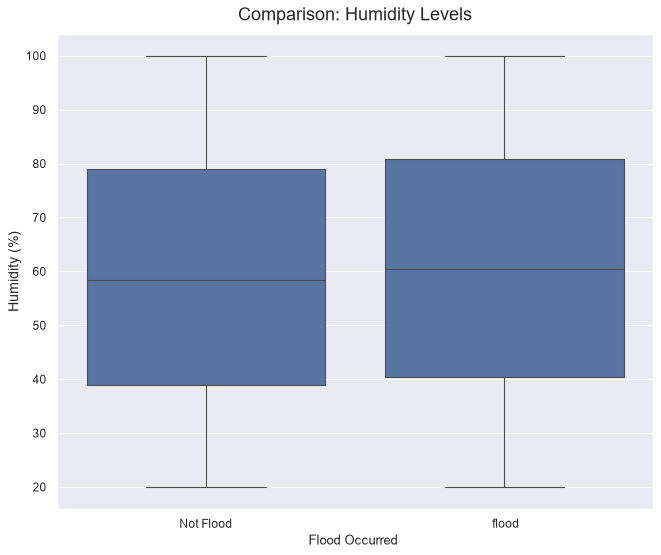

In [24]:
#boxplot

plt.figure(figsize=(10,8), dpi=77)
sns.boxplot(x="Flood Occurred", y="Humidity (%)", data=india_flood)
plt.title("Comparison: Humidity Levels", size=17, pad=13)
plt.ylabel('Humidity (%)', size=13)
plt.xlabel('Flood Occurred ')
plt.xticks([0, 1], ['Not Flood', ' flood'])
plt.show()

The boxplot compares humidity levels between non-flood (0) and flood (1) events, revealing nearly identical interquartile ranges and overall spreads ranging from $20\%$ to $100\%$. A slight upward shift is observed in the median humidity, increasing marginally from $58.5\%$ in non-flood cases to $60.4\%$ during flood occurrences. This substantial overlap indicates that relative humidity alone has a weak linear relationship with flood occurrences in this dataset. Consequently, humidity cannot serve as an effective standalone predictor and must be evaluated in combination with core hydrological variables such as rainfall, water level, and elevation.

Model run

In [ ]:
floodIndia = india_flood.copy()


floodIndia.drop(columns=['Latitude','Longitude'],inplace=True)



floodIndia.head()

,Rainfall (mm),Temperature (°C),Humidity (%),River Discharge (m³/s),Water Level (m),Elevation (m),Land Cover,Soil Type,Population Density,Infrastructure,Historical Floods,Flood Occurred
0,218.999493,34.144337,43.912963,4236.182888,7.415552,377.465434,Water Body,Clay,7276.742184,1,0,1
1,55.353599,28.778774,27.585422,2472.585219,8.811019,7330.608875,Forest,Peat,6897.736956,0,1,0
2,103.991908,43.934956,30.108738,977.328053,4.631799,2205.873488,Agricultural,Loam,4361.518494,1,1,1
3,198.984191,21.569354,34.453690,3683.208933,2.891787,2512.277800,Desert,Sandy,6163.069701,1,1,0
4,144.626803,32.635692,36.292267,2093.390678,3.188466,2001.818223,Agricultural,Loam,6167.964591,1,0,0


In [ ]:
floodI=floodIndia.copy() 
floodI=pd.get_dummies(floodIndia)

floodI

,Rainfall (mm),Temperature (°C),Humidity (%),River Discharge (m³/s),Water Level (m),Elevation (m),Population Density,Infrastructure,Historical Floods,Flood Occurred,Land Cover_Agricultural,Land Cover_Desert,Land Cover_Forest,Land Cover_Urban,Land Cover_Water Body,Soil Type_Clay,Soil Type_Loam,Soil Type_Peat,Soil Type_Sandy,Soil Type_Silt
0,218.999493,34.144337,43.912963,4236.182888,7.415552,377.465434,7276.742184,1,0,1,False,False,False,False,True,True,False,False,False,False
1,55.353599,28.778774,27.585422,2472.585219,8.811019,7330.608875,6897.736956,0,1,0,False,False,True,False,False,False,False,True,False,False
2,103.991908,43.934956,30.108738,977.328053,4.631799,2205.873488,4361.518494,1,1,1,True,False,False,False,False,False,True,False,False,False
3,198.984191,21.569354,34.453690,3683.208933,2.891787,2512.277800,6163.069701,1,1,0,False,True,False,False,False,False,False,False,True,False
4,144.626803,32.635692,36.292267,2093.390678,3.188466,2001.818223,6167.964591,1,0,0,True,False,False,False,False,False,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,285.682635,37.621017,69.795616,4830.703665,5.943965,2850.197900,6943.559433,0,0,0,True,False,False,False,False,True,False,False,False,False
9996,224.347263,37.935808,38.095486,1866.199787,9.466158,3314.692947,3011.997459,1,0,0,False,False,True,False,False,True,False,False,False,False
9997,5.836759,23.087083,79.919607,1523.374305,9.209185,3377.296962,7149.938303,1,0,1,False,True,False,False,False,True,False,False,False,False
9998,120.301453,28.029593,61.680873,2036.812638,2.004644,1146.986151,906.031452,1,0,1,False,False,False,False,True,False,False,False,True,False


In [ ]:
duplicate = floodI[floodIndia.duplicated()]
duplicate

,Rainfall (mm),Temperature (°C),Humidity (%),River Discharge (m³/s),Water Level (m),Elevation (m),Population Density,Infrastructure,Historical Floods,Flood Occurred,Land Cover_Agricultural,Land Cover_Desert,Land Cover_Forest,Land Cover_Urban,Land Cover_Water Body,Soil Type_Clay,Soil Type_Loam,Soil Type_Peat,Soil Type_Sandy,Soil Type_Silt


In [ ]:
floodI.drop_duplicates(inplace=True)
floodI

,Rainfall (mm),Temperature (°C),Humidity (%),River Discharge (m³/s),Water Level (m),Elevation (m),Population Density,Infrastructure,Historical Floods,Flood Occurred,Land Cover_Agricultural,Land Cover_Desert,Land Cover_Forest,Land Cover_Urban,Land Cover_Water Body,Soil Type_Clay,Soil Type_Loam,Soil Type_Peat,Soil Type_Sandy,Soil Type_Silt
0,218.999493,34.144337,43.912963,4236.182888,7.415552,377.465434,7276.742184,1,0,1,False,False,False,False,True,True,False,False,False,False
1,55.353599,28.778774,27.585422,2472.585219,8.811019,7330.608875,6897.736956,0,1,0,False,False,True,False,False,False,False,True,False,False
2,103.991908,43.934956,30.108738,977.328053,4.631799,2205.873488,4361.518494,1,1,1,True,False,False,False,False,False,True,False,False,False
3,198.984191,21.569354,34.453690,3683.208933,2.891787,2512.277800,6163.069701,1,1,0,False,True,False,False,False,False,False,False,True,False
4,144.626803,32.635692,36.292267,2093.390678,3.188466,2001.818223,6167.964591,1,0,0,True,False,False,False,False,False,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,285.682635,37.621017,69.795616,4830.703665,5.943965,2850.197900,6943.559433,0,0,0,True,False,False,False,False,True,False,False,False,False
9996,224.347263,37.935808,38.095486,1866.199787,9.466158,3314.692947,3011.997459,1,0,0,False,False,True,False,False,True,False,False,False,False
9997,5.836759,23.087083,79.919607,1523.374305,9.209185,3377.296962,7149.938303,1,0,1,False,True,False,False,False,True,False,False,False,False
9998,120.301453,28.029593,61.680873,2036.812638,2.004644,1146.986151,906.031452,1,0,1,False,False,False,False,True,False,False,False,True,False


In [ ]:
floodI

,Rainfall (mm),Temperature (°C),Humidity (%),River Discharge (m³/s),Water Level (m),Elevation (m),Population Density,Infrastructure,Historical Floods,Flood Occurred,Land Cover_Agricultural,Land Cover_Desert,Land Cover_Forest,Land Cover_Urban,Land Cover_Water Body,Soil Type_Clay,Soil Type_Loam,Soil Type_Peat,Soil Type_Sandy,Soil Type_Silt
0,218.999493,34.144337,43.912963,4236.182888,7.415552,377.465434,7276.742184,1,0,1,False,False,False,False,True,True,False,False,False,False
1,55.353599,28.778774,27.585422,2472.585219,8.811019,7330.608875,6897.736956,0,1,0,False,False,True,False,False,False,False,True,False,False
2,103.991908,43.934956,30.108738,977.328053,4.631799,2205.873488,4361.518494,1,1,1,True,False,False,False,False,False,True,False,False,False
3,198.984191,21.569354,34.453690,3683.208933,2.891787,2512.277800,6163.069701,1,1,0,False,True,False,False,False,False,False,False,True,False
4,144.626803,32.635692,36.292267,2093.390678,3.188466,2001.818223,6167.964591,1,0,0,True,False,False,False,False,False,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,285.682635,37.621017,69.795616,4830.703665,5.943965,2850.197900,6943.559433,0,0,0,True,False,False,False,False,True,False,False,False,False
9996,224.347263,37.935808,38.095486,1866.199787,9.466158,3314.692947,3011.997459,1,0,0,False,False,True,False,False,True,False,False,False,False
9997,5.836759,23.087083,79.919607,1523.374305,9.209185,3377.296962,7149.938303,1,0,1,False,True,False,False,False,True,False,False,False,False
9998,120.301453,28.029593,61.680873,2036.812638,2.004644,1146.986151,906.031452,1,0,1,False,False,False,False,True,False,False,False,True,False


Machine Learning: Logistic Regression

In [ ]:
x=floodI.drop(columns=['Flood Occurred'])
y=floodI['Flood Occurred']

In [ ]:
reg = LogisticRegression()
reg.fit(x, y)

c:\Users\HP\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [ ]:
x.isnull().sum()

Rainfall (mm)              0
Temperature (°C)           0
Humidity (%)               0
River Discharge (m³/s)     0
Water Level (m)            0
Elevation (m)              0
Population Density         0
Infrastructure             0
Historical Floods          0
Land Cover_Agricultural    0
Land Cover_Desert          0
Land Cover_Forest          0
Land Cover_Urban           0
Land Cover_Water Body      0
Soil Type_Clay             0
Soil Type_Loam             0
Soil Type_Peat             0
Soil Type_Sandy            0
Soil Type_Silt             0
dtype: int64

In [ ]:
print(reg.coef_)

print(reg.intercept_)

[[-2.66614320e-07 -2.78290536e-03  2.65224505e-03 -1.31817495e-07
  -8.01972988e-03 -1.60304202e-06 -1.74516402e-06 -1.11091522e-03
   4.20887795e-03  2.44221912e-03  2.76950395e-03 -4.50850484e-04
   2.79707531e-03 -7.19662704e-03  3.29539531e-03 -4.07090183e-03
   1.63637422e-03  2.16354596e-03 -2.66309280e-03]]
[0.00036132]


In [ ]:
y_pred= reg.predict(x)
print(y_pred)

[0 0 0 ... 1 1 1]


In [ ]:
from sklearn.metrics import accuracy_score
y_test=floodI['Flood Occurred']
accuracy_score(y_test,y_pred)

0.5184

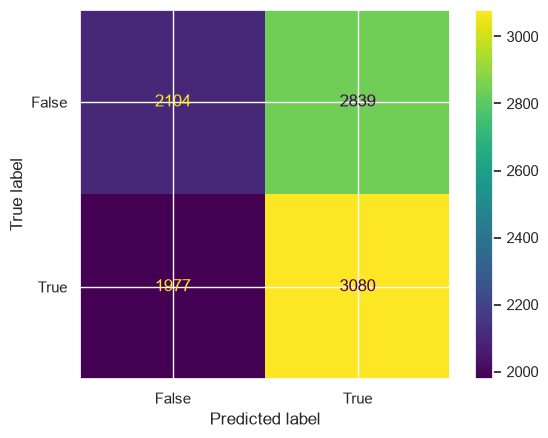

In [ ]:
import matplotlib.pyplot as plt
from sklearn import metrics
confusion_matrix = metrics.confusion_matrix(y_test,y_pred)
cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix = confusion_matrix, display_labels = [False, True])
cm_display.plot()
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

# Calculate precision
precision = precision_score(y_test, y_pred)
print("Precision:", precision)

# Calculate recall (sensitivity)
recall = recall_score(y_test, y_pred)
print("Recall (Sensitivity):", recall)

# Calculate F1-score
f1 = f1_score(y_test, y_pred)
print("F1-Score:", f1)

Accuracy: 0.5184
Precision: 0.5203581686095624
Recall (Sensitivity): 0.6090567530156219
F1-Score: 0.5612244897959183
